# LAB 09 — NER fine-tuning trên CoNLL-2003
Pretrained **`bert-base-cased`** (12 layer, hidden 768, vocabulary 28,996, phân biệt hoa thường: quan trọng cho tên riêng) + head **Linear(768, 9)** áp dụng cho **mọi token** (`information_extraction.TokenClassifier`).
- Dataset: CoNLL-2003 (HF `eriktks/conll2003`, bản parquet): train 14,041 / validation 3,250 / test 3,453 câu; 9 nhãn BIO.
- Alignment: **Strategy A** (subword đầu tiên mỗi word nhận nhãn, subword sau = −100); so sánh thêm Strategy B. Đánh giá theo **word** (nhãn của subword đầu), entity-level bằng `ner_utils.entity_metrics` (khớp `seqeval`).
- Huấn luyện trên **Kaggle GPU**; kết quả trong `cache/`, chạy lại ở local sẽ nạp cache.

In [1]:
import sys, os, time, csv, json, random, warnings
from collections import Counter, defaultdict
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from transformers import AutoTokenizer
from ner_utils import LABELS, LABEL2ID, TYPES, IGNORE, get_entities, entity_metrics, token_metrics, align_labels, word_predictions, prf
from information_extraction import TokenClassifier, MODEL_NAME
warnings.filterwarnings("ignore")
SEED = 2026; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu"); HW = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"
print("device:", DEVICE, HW)
RESULTS = []
def log(exp, cfg, metric, val): RESULTS.append((exp, cfg, metric, val))
os.makedirs("cache", exist_ok=True)
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

C:\Users\dinhb\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu CPU


In [2]:
from datasets import load_dataset
ds = load_dataset("eriktks/conll2003", revision="refs/convert/parquet")
D = {sp: ([list(x) for x in ds[sp]["tokens"]], [[LABELS[i] for i in x] for x in ds[sp]["ner_tags"]]) for sp in ("train", "validation", "test")}
for sp in D:                                   # bỏ câu rỗng nếu có
    keep = [i for i, w in enumerate(D[sp][0]) if len(w) > 0]; D[sp] = ([D[sp][0][i] for i in keep], [D[sp][1][i] for i in keep])
rows = []
for sp, (W, T) in D.items():
    tags = [t for ts in T for t in ts]; ents = Counter(e[0] for ts in T for e in get_entities(ts))
    rows.append(dict(split=sp, sentences=len(W), words=len(tags), pct_O=round(tags.count("O") / len(tags) * 100, 1), entities=sum(ents.values()), **{t: ents[t] for t in TYPES}))
display(pd.DataFrame(rows).set_index("split"))

,sentences,words,pct_O,entities,PER,ORG,LOC,MISC
split,,,,,,,,
train,14041,203621,83.3,23499,6600,6321,7140,3438
validation,3250,51362,83.3,5942,1842,1341,1837,922
test,3453,46435,82.5,5648,1617,1661,1668,702


## 16. Core implementation — tokenizer(is_split_into_words) → word_ids → alignment → token labels → logits → predictions

In [3]:
def encode(words_list, tags_list, strategy="first", max_length=256):
    enc = tok(words_list, is_split_into_words=True, truncation=True, max_length=max_length)
    labels = [align_labels(enc.word_ids(i), [LABEL2ID[t] for t in tags], strategy) for i, tags in enumerate(tags_list)]
    return enc, labels
def collate(enc, labels, idx):
    L = max(len(enc["input_ids"][i]) for i in idx)
    ids = torch.full((len(idx), L), tok.pad_token_id); am = torch.zeros((len(idx), L), dtype=torch.long); y = torch.full((len(idx), L), IGNORE)
    for r, i in enumerate(idx):
        n = len(enc["input_ids"][i]); ids[r, :n] = torch.tensor(enc["input_ids"][i]); am[r, :n] = 1; y[r, :n] = torch.tensor(labels[i])
    return ids, am, y
@torch.no_grad()
def predict(model, words_list, bs=64):
    model.eval(); enc = tok(words_list, is_split_into_words=True, truncation=True, max_length=256); out = []
    dummy = [[0] * len(x) for x in enc["input_ids"]]
    for s in range(0, len(words_list), bs):
        idx = list(range(s, min(s + bs, len(words_list)))); ids, am, _ = collate(enc, dummy, idx)
        with torch.autocast(device_type="cuda", enabled=DEVICE.type == "cuda"):
            pred = model(ids.to(DEVICE), am.to(DEVICE)).argmax(-1).cpu()
        for r, i in enumerate(idx):
            tags = word_predictions(enc.word_ids(i), pred[r].tolist()); out.append(tags + ["O"] * (len(words_list[i]) - len(tags)))
    return out
EPOCHS, BATCH, LR = 3, 16, 3e-5
def train_run(name, strategy):
    path = f"cache/{name}.pt"
    if os.path.exists(path): return torch.load(path, map_location="cpu", weights_only=False)
    torch.manual_seed(SEED); rng = np.random.RandomState(SEED)
    enc, labels = encode(*D["train"], strategy=strategy)
    model = TokenClassifier(MODEL_NAME).to(DEVICE); opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    steps = EPOCHS * int(np.ceil(len(labels) / BATCH)); warm = int(0.1 * steps)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else max(0.0, (steps - s) / (steps - warm)))
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda"); lossf = nn.CrossEntropyLoss(ignore_index=IGNORE)
    hist = dict(train_loss=[], val_f1=[], epoch_s=[]); best = (-1, None, 0)
    for ep in range(EPOCHS):
        model.train(); t0 = time.time(); tl = n = 0
        order = rng.permutation(len(labels))
        for s in range(0, len(order), BATCH):
            ids, am, y = collate(enc, labels, order[s:s + BATCH])
            with torch.autocast(device_type="cuda", enabled=DEVICE.type == "cuda"):
                logits = model(ids.to(DEVICE), am.to(DEVICE))
                loss = lossf(logits.float().view(-1, len(LABELS)), y.to(DEVICE).view(-1))   # token IGNORE không vào loss
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item(); n += 1
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        dt = time.time() - t0; vf = entity_metrics(D["validation"][1], predict(model, D["validation"][0]))["micro"]["f1"]
        hist["train_loss"].append(tl / n); hist["val_f1"].append(vf); hist["epoch_s"].append(dt)
        print(f"{name} ep{ep+1}: train loss {tl/n:.4f} | val entity F1 {vf:.4f} | {dt:.0f}s")
        if vf > best[0]: best = (vf, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, ep + 1)
    model.load_state_dict(best[1])
    res = dict(name=name, strategy=strategy, hist=hist, best_epoch=best[2], train_time=sum(hist["epoch_s"]), hardware=HW,
               params=sum(p.numel() for p in model.parameters()), val_pred=predict(model, D["validation"][0]), test_pred=predict(model, D["test"][0]),
               n_ignored=int(sum(l == IGNORE for ls in labels for l in ls)), n_tokens=int(sum(len(ls) for ls in labels)))
    if name == "BERT_A": torch.save({k: v.half() for k, v in model.state_dict().items()}, "cache/BERT_A_weights_fp16.pt")
    torch.save(res, path); del model; torch.cuda.empty_cache() if DEVICE.type == "cuda" else None
    return res

In [4]:
# Minh họa pipeline trên một câu (model pretrained, head chưa train -> chỉ để xem shape và các bước)
words = ["Elon", "Musk", "founded", "SpaceX", "in", "California", "."]; tags = ["B-PER", "I-PER", "O", "B-ORG", "O", "B-LOC", "O"]
tokens = tok(words, is_split_into_words=True, truncation=True, padding=True, return_tensors="pt")
wid = tokens.word_ids(); lab = align_labels(wid, [LABEL2ID[t] for t in tags], "first")
demo_model = TokenClassifier(MODEL_NAME).eval()
with torch.no_grad(): logits = demo_model(tokens["input_ids"], tokens["attention_mask"])
print("keys:", list(tokens.keys()), "| logits shape:", tuple(logits.shape), "(batch, T, C)")
display(pd.DataFrame({"token": tok.convert_ids_to_tokens(tokens["input_ids"][0]), "input_id": tokens["input_ids"][0].tolist(), "attention_mask": tokens["attention_mask"][0].tolist(),
                      "word_id": wid, "label (A)": [LABELS[l] if l != IGNORE else "−100" for l in lab],
                      "label (B)": [LABELS[l] if l != IGNORE else "−100" for l in align_labels(wid, [LABEL2ID[t] for t in tags], "all")],
                      "prediction (head chưa train)": [LABELS[i] for i in logits[0].argmax(-1).tolist()]}).T)
del demo_model

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  39%|███▉      | 78/199 [00:00<00:00, 766.13it/s]

Loading weights:  78%|███████▊  | 155/199 [00:00<00:00, 698.02it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 875.83it/s]


[transformers] BertModel LOAD REPORT from: bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


keys: ['input_ids', 'token_type_ids', 'attention_mask'] | logits shape: (1, 12, 9) (batch, T, C)


,0,1,2,3,4,5,6,7,8,9,10,11
token,[CLS],El,##on,Mu,##sk,founded,Space,##X,in,California,.,[SEP]
input_id,101,2896,1320,19569,5276,1771,4525,3190,1107,1756,119,102
attention_mask,1,1,1,1,1,1,1,1,1,1,1,1
word_id,NaN,0.0,0.0,1.0,1.0,2.0,3.0,3.0,4.0,5.0,6.0,NaN
label (A),−100,B-PER,−100,I-PER,−100,O,B-ORG,−100,O,B-LOC,O,−100
label (B),−100,B-PER,I-PER,I-PER,I-PER,O,B-ORG,I-ORG,O,B-LOC,O,−100
prediction (head chưa train),B-ORG,B-ORG,B-MISC,B-MISC,B-MISC,B-MISC,B-MISC,B-LOC,I-LOC,I-LOC,I-MISC,I-LOC


In [5]:
runs = {"BERT_A": train_run("BERT_A", "first"), "BERT_B": train_run("BERT_B", "all")}
print({k: (round(v["hist"]["val_f1"][v["best_epoch"] - 1], 4), round(v["train_time"])) for k, v in runs.items()})

{'BERT_A': (0.9519, 229), 'BERT_B': (0.9515, 228)}


## 18–19. Experiment 2 + 3 — Baseline vs Transformer; token-level vs entity-level (test set)

In [6]:
base = json.load(open("cache/baseline.json")); gold = D["test"][1]
preds = {"Baseline (features + LR)": base["test"]["pred"], "BERT fine-tuned (Strategy A)": runs["BERT_A"]["test_pred"]}
rows = []
for name, p in preds.items():
    em, tm = entity_metrics(gold, p)["micro"], token_metrics(gold, p)
    rows.append({"Model": name, "Entity Precision": round(em["precision"], 4), "Entity Recall": round(em["recall"], 4), "Entity F1": round(em["f1"], 4),
                 "Token accuracy": round(tm["accuracy"], 4), "Token F1 (không tính O)": round(tm["f1"], 4), "TP / pred / gold": f"{em['tp']} / {em['n_pred']} / {em['n_gold']}"})
    for k in ("precision", "recall", "f1"): log("exp2_baseline_vs_bert", name, f"entity_{k}", round(em[k], 4))
    log("exp2_baseline_vs_bert", name, "token_accuracy", round(tm["accuracy"], 4)); log("exp2_baseline_vs_bert", name, "token_f1_nonO", round(tm["f1"], 4))
t2 = pd.DataFrame(rows).set_index("Model"); display(t2)
print(f"baseline: train {base['train_time_s']:.0f} s CPU, {base['n_features']:,} feature | BERT: train {runs['BERT_A']['train_time']:.0f} s trên {runs['BERT_A']['hardware']}, {runs['BERT_A']['params']:,} tham số")
pctO = np.mean([t == "O" for ts in gold for t in ts]); print(f"tỉ lệ word nhãn O trong test: {pctO:.1%} → model đoán toàn O đã có token accuracy {pctO:.1%} nhưng entity F1 = 0")
def boundary_stats(gold, pred):
    c = Counter()
    for g, p in zip(gold, pred):
        G, P = set(get_entities(g)), set(get_entities(p))
        for e in G - P:
            ov = [q for q in P if q[1] < e[2] and e[1] < q[2]]
            c["sai loại, đúng ranh giới" if any(q[1:] == e[1:] for q in ov) else "đúng loại, sai ranh giới" if any(q[0] == e[0] for q in ov) else "sai cả hai" if ov else "bỏ sót hoàn toàn"] += 1
    return c
for name, p in preds.items(): print(name, "| gold entity không được nhận đúng:", dict(boundary_stats(gold, p)))

,Entity Precision,Entity Recall,Entity F1,Token accuracy,Token F1 (không tính O),TP / pred / gold
Model,,,,,,
Baseline (features + LR),0.7219,0.7778,0.7488,0.9586,0.8113,4393 / 6085 / 5648
BERT fine-tuned (Strategy A),0.9077,0.9226,0.9151,0.9831,0.9263,5211 / 5741 / 5648


baseline: train 279 s CPU, 81,063 feature | BERT: train 229 s trên Tesla T4, 108,317,193 tham số
tỉ lệ word nhãn O trong test: 82.5% → model đoán toàn O đã có token accuracy 82.5% nhưng entity F1 = 0
Baseline (features + LR) | gold entity không được nhận đúng: {'sai loại, đúng ranh giới': 504, 'đúng loại, sai ranh giới': 423, 'bỏ sót hoàn toàn': 213, 'sai cả hai': 115}
BERT fine-tuned (Strategy A) | gold entity không được nhận đúng: {'sai loại, đúng ranh giới': 225, 'đúng loại, sai ranh giới': 87, 'bỏ sót hoàn toàn': 60, 'sai cả hai': 65}


**Nhận xét Experiment 2 + 3:**
- BERT fine-tuned: entity **P 0.908 / R 0.923 / F1 0.915**; baseline (feature + LR): 0.722 / 0.778 / **0.749**. Transformer tăng **16.6 điểm entity F1**.
- **Token-level che giấu khác biệt:** token accuracy 0.959 so với 0.983 (chỉ chênh 2.4 điểm) vì 82.5% word là O: model đoán toàn O đã được 82.5% accuracy nhưng entity F1 = 0. Entity F1 của baseline (0.749) thấp hơn hẳn token F1 không tính O (0.811) vì một lỗi ở một word làm hỏng cả entity.
- Baseline sinh nhiều entity thừa (6,085 dự đoán so với 5,648 gold). Trong các gold entity không được nhận đúng, baseline có 423 lỗi **ranh giới** và 504 lỗi **sai loại**; BERT giảm còn 87 và 225: ngữ cảnh giúp nhất ở ranh giới.

## 21. Experiment 4 — Entity type analysis (BERT, test set) → `entity_metrics.csv`

In [7]:
train_cnt = Counter(e[0] for ts in D["train"][1] for e in get_entities(ts))
train_forms = defaultdict(set)
for W, T in zip(*D["train"]):
    for t, s, e in get_entities(T): train_forms[t].add(" ".join(W[s:e]))
rows = []
for name, p in preds.items():
    em = entity_metrics(gold, p)
    for t in TYPES + ["micro"]:
        r = em[t]; rows.append({"Model": name, "Entity": t if t != "micro" else "ALL (micro)", "Precision": round(r["precision"], 4), "Recall": round(r["recall"], 4), "F1": round(r["f1"], 4),
                                "TP": r["tp"], "n_pred": r["n_pred"], "n_gold (test)": r["n_gold"], "n_train": train_cnt[t] if t != "micro" else sum(train_cnt.values()),
                                "distinct forms (train)": len(train_forms[t]) if t != "micro" else None})
em_df = pd.DataFrame(rows); em_df.to_csv("entity_metrics.csv", index=False)
display(em_df[em_df.Model.str.startswith("BERT")].drop(columns="Model").set_index("Entity"))
display(em_df.pivot(index="Entity", columns="Model", values="F1"))

,Precision,Recall,F1,TP,n_pred,n_gold (test),n_train,distinct forms (train)
Entity,,,,,,,,
PER,0.9623,0.9623,0.9623,1556,1617,1617,6600,3614.0
ORG,0.8837,0.9199,0.9015,1528,1729,1661,6321,2403.0
LOC,0.9406,0.9299,0.9352,1551,1649,1668,7140,1332.0
MISC,0.7721,0.8205,0.7956,576,746,702,3438,871.0
ALL (micro),0.9077,0.9226,0.9151,5211,5741,5648,23499,NaN


Model,BERT fine-tuned (Strategy A),Baseline (features + LR)
Entity,,
ALL (micro),0.9151,0.7488
LOC,0.9352,0.8253
MISC,0.7956,0.7686
ORG,0.9015,0.6434
PER,0.9623,0.7702


**Nhận xét Experiment 4 (BERT):** PER 0.962 > LOC 0.935 > ORG 0.902 > MISC 0.796.
- **Số lượng training examples:** MISC ít nhất (3,438 entity, 871 dạng khác nhau) và kém nhất; nhưng PER có số entity tương đương ORG/LOC mà tốt nhất, nên số lượng không giải thích hết.
- **Lexical patterns:** PER có mẫu rõ (Tên + Họ viết hoa, sau "said", "Mr", trong ngoặc sau tên đội); MISC là loại "còn lại" rất đa dạng (quốc tịch "Italian", sự kiện, giải đấu, tên sản phẩm) nên khó có pattern chung.
- **Ambiguity / context:** ORG và LOC hay nhầm lẫn nhau (tên thành phố cũng là tên đội bóng: B-LOC → B-ORG 54 word, B-ORG → B-LOC 42); "Czech", "Italian" có thể là MISC (tính từ) hoặc LOC.
- **Entity boundary / domain:** MISC hay dài và không rõ ranh giới (giải đấu, tên sự kiện); dữ liệu Reuters 1996 có rất nhiều bảng kết quả thể thao toàn tên đội, nơi ORG/LOC chỉ phân biệt được qua ngữ cảnh. Baseline kém nhất ở ORG (0.643): không có ngữ cảnh rộng để biết "Leicester" là đội bóng.

## 22. Experiment 5 — Entity length (số word) → `entity_length_analysis.png`
Recall theo độ dài entity **gold**, precision theo độ dài entity **dự đoán**, F1 = 2PR/(P+R).

Baseline (features + LR)                            \
                                n_gold Precision  Recall      F1   
Entity length                                                      
1                                 3574    0.6727  0.8081  0.7342   
2                                 1776    0.8539  0.7765  0.8133   
3                                  236    0.7308  0.4831  0.5816   
4+                                  62    0.5714  0.1935  0.2892   

              BERT fine-tuned (Strategy A)                            
                                    n_gold Precision  Recall      F1  
Entity length                                                         
1                                     3574    0.9026  0.9205  0.9115  
2                                     1776    0.9251  0.9313  0.9282  
3                                      236    0.8745  0.8856  0.8800  
4+                                      62    0.8406  0.9355  0.8855

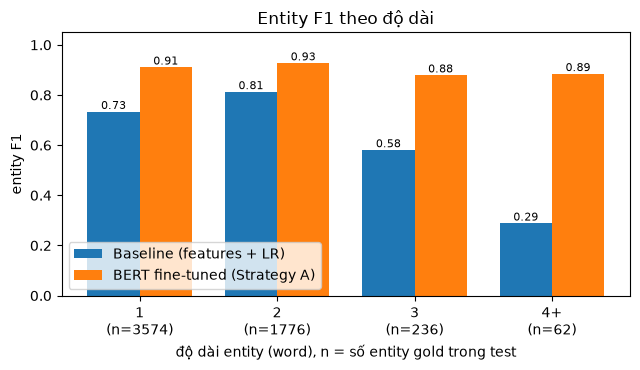

In [8]:
def by_length(gold, pred):
    tp_g, ng, tp_p, npd = Counter(), Counter(), Counter(), Counter()
    b = lambda e: min(e[2] - e[1], 4)
    for g, p in zip(gold, pred):
        G, P = set(get_entities(g)), set(get_entities(p))
        for e in G: ng[b(e)] += 1; tp_g[b(e)] += e in P
        for e in P: npd[b(e)] += 1; tp_p[b(e)] += e in G
    rows = []
    for k in (1, 2, 3, 4):
        P_ = tp_p[k] / npd[k] if npd[k] else 0; R_ = tp_g[k] / ng[k] if ng[k] else 0
        rows.append({"Entity length": f"{k}" if k < 4 else "4+", "n_gold": ng[k], "Precision": round(P_, 4), "Recall": round(R_, 4), "F1": round(2*P_*R_/(P_+R_) if P_+R_ else 0, 4)})
    return pd.DataFrame(rows).set_index("Entity length")
lens = {name: by_length(gold, p) for name, p in preds.items()}
display(pd.concat(lens, axis=1))
fig, ax = plt.subplots(figsize=(6.5, 3.8)); x = np.arange(4); w = 0.38
for j, (name, t) in enumerate(lens.items()):
    bars = ax.bar(x + (j - .5) * w, t.F1, w, label=name)
    for xi, (f, n) in enumerate(zip(t.F1, t.n_gold)): ax.text(xi + (j - .5) * w, f + .01, f"{f:.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([f"{k}\n(n={n})" for k, n in zip(t.index, t.n_gold)]); ax.set_xlabel("độ dài entity (word), n = số entity gold trong test")
ax.set_ylabel("entity F1"); ax.set_ylim(0, 1.05); ax.legend(loc="lower left"); ax.set_title("Entity F1 theo độ dài"); plt.tight_layout(); plt.savefig("entity_length_analysis.png", dpi=130); plt.show()
for name, t in lens.items():
    for k, r in t.iterrows(): log("exp5_entity_length", f"{name}|len={k}", "f1|n_gold", f"{r.F1}|{r.n_gold}")

**Nhận xét Experiment 5:**
- **Baseline** đúng như Prediction 2: F1 giảm mạnh khi entity dài: 0.73 (1 word), 0.81 (2), **0.58 (3), 0.29 (4+)**; recall 4+ chỉ 0.19, tức hầu như không nhận đủ entity dài vì mỗi word được phân loại độc lập.
- **BERT** gần như không bị ảnh hưởng: 0.912 / 0.928 / 0.880 / 0.886. Entity 2 word còn tốt nhất (đa số là tên người Tên + Họ). Ngữ cảnh hai chiều giúp giữ ranh giới cả cụm. Prediction 2 **chỉ đúng với baseline**, sai với BERT.
- Lưu ý entity 4+ word chỉ có 62 trong test nên số liệu dao động nhiều.

### Prediction 3 — Entity hiếm: entity đã xuất hiện trong train (cùng chuỗi và loại) vs chưa xuất hiện

In [9]:
seen_forms = {(t, " ".join(W[s:e])) for W, T in zip(*D["train"]) for t, s, e in get_entities(T)}
def seen_unseen(gold, pred, words):
    c = {k: Counter() for k in ("seen", "unseen")}
    for W, g, p in zip(words, gold, pred):
        G, P = set(get_entities(g)), set(get_entities(p))
        for e in G: k = "seen" if (e[0], " ".join(W[e[1]:e[2]])) in seen_forms else "unseen"; c[k]["gold"] += 1; c[k]["tp"] += e in P
        for e in P: k = "seen" if (e[0], " ".join(W[e[1]:e[2]])) in seen_forms else "unseen"; c[k]["pred"] += 1; c[k]["ptp"] += e in G
    return {k: dict(n_gold=v["gold"], recall=round(v["tp"] / v["gold"], 4), precision=round(v["ptp"] / v["pred"], 4) if v["pred"] else 0) for k, v in c.items()}
rows = []
for name, p in preds.items():
    for k, v in seen_unseen(gold, p, D["test"][0]).items():
        f = 2 * v["precision"] * v["recall"] / (v["precision"] + v["recall"]); rows.append({"Model": name, "Entity": k, **v, "F1": round(f, 4)})
        log("pred3_rare_entity", f"{name}|{k}", "f1|recall|n_gold", f"{f:.4f}|{v['recall']}|{v['n_gold']}")
display(pd.DataFrame(rows).set_index(["Model", "Entity"]))

n_gold  recall  precision      F1
Model                        Entity                                   
Baseline (features + LR)     seen      2963  0.9200     0.9241  0.9220
                             unseen    2685  0.6209     0.5317  0.5728
BERT fine-tuned (Strategy A) seen      2963  0.9602     0.9677  0.9639
                             unseen    2685  0.8812     0.8447  0.8626

**Nhận xét Prediction 3:** 2,685/5,648 entity test (48%) **chưa từng xuất hiện** trong train (cùng chuỗi, cùng loại). BERT: F1 0.964 (đã gặp) so với **0.863 (chưa gặp)**; baseline: 0.922 so với **0.573**. Entity hiếm gây lỗi nhiều hơn ở cả hai model (Prediction 3 đúng); khoảng cách của baseline (35 điểm) lớn gấp 3 lần BERT (10 điểm). Baseline chủ yếu "nhớ" từ đã gặp; BERT khái quát nhờ ngữ cảnh và kiến thức tên riêng từ pretraining. Đây là nơi Transformer mang lại giá trị lớn nhất.

## Confusion matrix (word-level, BERT, test) → `confusion_matrix.png`

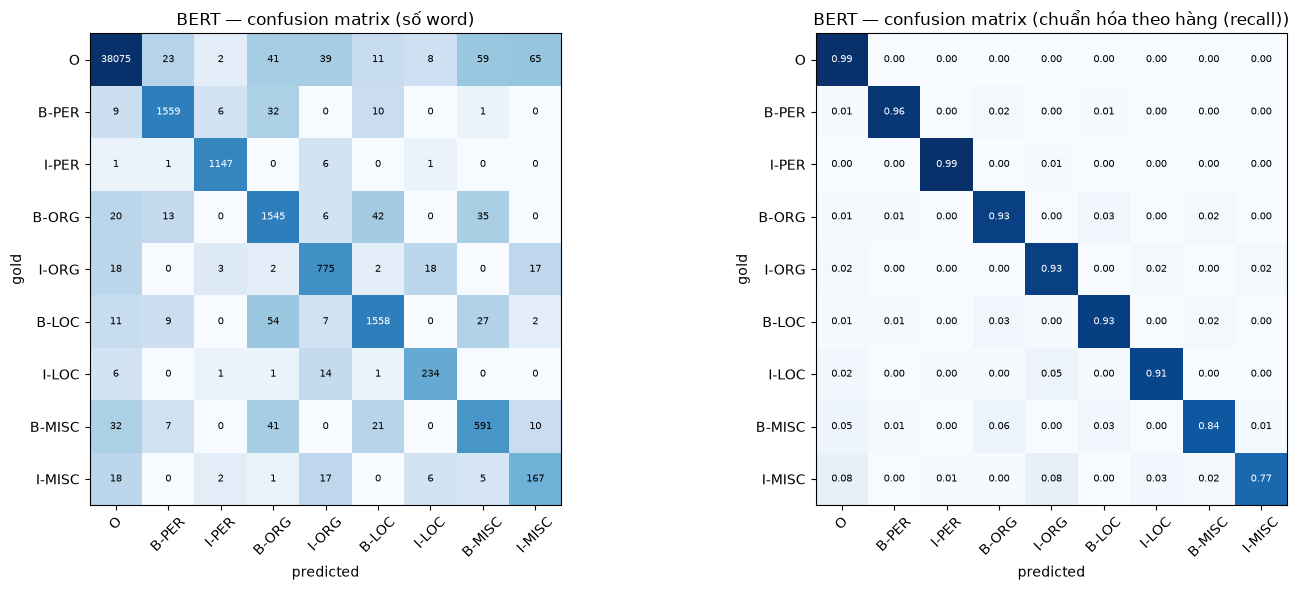

nhầm lẫn nhiều nhất (gold → pred, số word): [('O', 'I-MISC', np.int64(65)), ('O', 'B-MISC', np.int64(59)), ('B-LOC', 'B-ORG', np.int64(54)), ('B-ORG', 'B-LOC', np.int64(42)), ('O', 'B-ORG', np.int64(41)), ('B-MISC', 'B-ORG', np.int64(41)), ('O', 'I-ORG', np.int64(39)), ('B-ORG', 'B-MISC', np.int64(35))]


In [10]:
from sklearn.metrics import confusion_matrix
pb = runs["BERT_A"]["test_pred"]; g_flat = [t for ts in gold for t in ts]; p_flat = [t for ts in pb for t in ts]
cm = confusion_matrix(g_flat, p_flat, labels=LABELS); cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, M, title, fmt in ((ax[0], cm, "số word", "d"), (ax[1], cmn, "chuẩn hóa theo hàng (recall)", ".2f")):
    a.imshow(np.log1p(M) if fmt == "d" else M, cmap="Blues"); a.set_xticks(range(9)); a.set_yticks(range(9)); a.set_xticklabels(LABELS, rotation=45); a.set_yticklabels(LABELS)
    a.set_xlabel("predicted"); a.set_ylabel("gold"); a.set_title(f"BERT — confusion matrix ({title})")
    for i in range(9):
        for j in range(9): a.text(j, i, format(M[i, j], fmt), ha="center", va="center", fontsize=7, color="white" if (fmt == ".2f" and M[i, j] > .5) or (fmt == "d" and M[i, j] > 1000) else "black")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=120); plt.show()
off = [(LABELS[i], LABELS[j], cm[i, j]) for i in range(9) for j in range(9) if i != j]; off.sort(key=lambda t: -t[2])
print("nhầm lẫn nhiều nhất (gold → pred, số word):", off[:8])
for a, b_, n in off[:8]: log("confusion_top", f"{a}->{b_}", "count", int(n))

**Nhận xét confusion matrix:** nhầm lẫn lớn nhất là **O → MISC** (word thường bị gán MISC: 65 I-MISC, 59 B-MISC) và **LOC ↔ ORG** (54 + 42); tiếp theo MISC → ORG. Hầu như không nhầm B ↔ I cùng loại, tức lỗi chủ yếu là **loại**, không phải BIO.

## 23. Experiment 6 — Error analysis (BERT, test): 5 false positive, 5 false negative, 5 boundary error
- **False positive (spurious):** entity dự đoán không chồng lên gold entity nào. **False negative (missing):** gold entity không có dự đoán nào chồng lên. **Boundary:** chồng lên nhau, cùng loại nhưng khác ranh giới. Chọn ngẫu nhiên seed 2026.

In [11]:
W_ = D["test"][0]; cats = defaultdict(list)
for i, (g, p) in enumerate(zip(gold, pb)):
    G, P = set(get_entities(g)), set(get_entities(p))
    for e in P - G:
        ov = [q for q in G if q[1] < e[2] and e[1] < q[2]]
        if not ov: cats["FP"].append((i, None, e))
        elif any(q[0] == e[0] for q in ov): cats["BOUNDARY"].append((i, next(q for q in ov if q[0] == e[0]), e))
        elif any(q[1:] == e[1:] for q in ov): cats["TYPE"].append((i, next(q for q in ov if q[1:] == e[1:]), e))
    for e in G - P:
        if not [q for q in P if q[1] < e[2] and e[1] < q[2]]: cats["FN"].append((i, e, None))
print({k: len(v) for k, v in cats.items()})
for k, v in cats.items(): log("error_counts", k, "n", len(v))
rng = np.random.RandomState(SEED); fmt = lambda i, e: f"{e[0]} \"{' '.join(W_[i][e[1]:e[2]])}\"" if e else "—"
ERR = {}
for k in ("FP", "FN", "BOUNDARY", "TYPE"):
    pick = [cats[k][j] for j in rng.choice(len(cats[k]), min(5, len(cats[k])), replace=False)]; ERR[k] = pick
    print(f"\n===== {k} =====")
    for i, ge, pe in pick:
        print(f"[test {i}] gold: {fmt(i, ge)} | pred: {fmt(i, pe)} | baseline: {[fmt(i, e) for e in get_entities(base['test']['pred'][i]) if (ge or pe)[1] < e[2] and e[1] < (ge or pe)[2]]}\n   {' '.join(W_[i])}")

{'FP': 143, 'TYPE': 225, 'BOUNDARY': 84, 'FN': 60}

===== FP =====
[test 1634] gold: — | pred: MISC "GENERAL OBLIGATION" | baseline: []
   GENERAL OBLIGATION BONDS
[test 3401] gold: — | pred: MISC "New Year" | baseline: ['LOC "New"']
   With just one league match scheduled before the New Year break , Real are also assured of spending Christmas ahead of their arch-rivals .
[test 1921] gold: — | pred: ORG "BTPs" | baseline: []
   In local currency terms , Italian BTPs offered returns of 0.85 percent in the week ended on Thursday , with fellow high-yielder Sweden close behind on 0.80 percent .
[test 1297] gold: — | pred: MISC "Pope" | baseline: ['LOC "Pope"']
   A meeting with the Pope is also planned , " Dariusz Rosati told a news conference .
[test 1243] gold: — | pred: ORG "Public Service" | baseline: ['ORG "Public"']
   Public Service Minister David Dofara , who is the head of the national Red Cross , told Reuters he had seen the bodies of former interior minister Christophe Grelombe 

**Bảng error analysis** (BERT; giải thích là hypothesis):

| # | Text (rút gọn) | Gold | Prediction | Error type | Explanation |
|---|---|---|---|---|---|
| FP1 | "GENERAL OBLIGATION BONDS" | — | MISC "GENERAL OBLIGATION" | spurious entity | Tiêu đề viết hoa toàn bộ: chữ hoa vốn là tín hiệu tên riêng; tokenizer cased tách thành nhiều mảnh lạ. |
| FP2 | "... before the New Year break ..." | — | MISC "New Year" | spurious / ambiguous entity | "New Year" viết hoa giống tên lễ; annotation CoNLL không gán, quy ước không nhất quán. |
| FP3 | "Italian BTPs offered returns ..." | — | ORG "BTPs" | rare entity / domain-specific | Tên trái phiếu Ý (thuật ngữ tài chính) viết hoa, hiếm. |
| FP4 | "A meeting with the Pope is also planned" | — | MISC "Pope" | ambiguous entity | Chức danh viết hoa; gold không coi là entity. |
| FP5 | "Public Service Minister David Dofara" | — | ORG "Public Service" | context-dependent | Phần đầu chức danh bị hiểu như tên bộ (tổ chức). |
| FN1 | "... all kick- off times GMT )" | MISC "GMT" | — | rare / ambiguous entity | Từ viết tắt múi giờ, hiếm, không rõ là entity. |
| FN2 | "League game on Thursday ( home team in CAPS )" | LOC "League" | — | ambiguous / annotation noise | Gold LOC cho "League" có vẻ là lỗi annotation (dòng bị cắt từ "National Hockey League"). |
| FN3 | "SOCCER - FIFA BOSS HAVELANGE STANDS BY WEAH ." | PER "WEAH" | — | missing entity / tokenization | Tiêu đề viết hoa: "WEAH" thành nhiều mảnh, mất hình dạng tên người (model nhận được HAVELANGE). |
| FN4 | "Premier league" | MISC "Premier league" | — | context-dependent | Câu 2 word không có ngữ cảnh. |
| FN5 | "Association games on Friday ..." | ORG "Association" | — | annotation fragment | Phần còn lại của tên dài bị tách dòng ("National Basketball Association"). |
| B1 | "-- New York Commodities Desk , 212-859-1640" | ORG "New York Commodities" | ORG "... Desk" | wrong boundary | Model lấy thêm "Desk"; ranh giới tên bộ phận không rõ. |
| B2 | "Scorers : Shkvyrin Igor 78" | PER "Shkvyrin Igor" | PER "Shkvyrin" | wrong boundary / rare entity | Tên Nga viết Họ trước Tên, hiếm; model cắt "Igor" ra. |
| B3 | "10= Florence Masnada ( France ) 51" | PER "Masnada" | PER "Florence Masnada" | wrong boundary (gold đáng ngờ) | "Florence" là tên của vận động viên; model có vẻ đúng hơn gold. |
| B4 | "the Santiago Bernabeu stadium" | LOC "Santiago Bernabeu stadium" | LOC "Santiago Bernabeu" | wrong boundary | Chữ thường "stadium" không được gộp vào entity. |
| B5 | "dubbed " The Super Peasants "" | ORG "The Super Peasants" | ORG "The" | wrong boundary / rare | Biệt danh trong ngoặc kép, hiếm; model dừng sau "The". |
| T1 | "Czech President Vaclav Havel ..." | LOC "Czech" | MISC "Czech" | wrong entity type | Tính từ quốc gia thường là MISC; gold LOC ở đây không nhất quán với quy ước. |
| T2 | "state radio RAI" | LOC "RAI" | ORG "RAI" | wrong type (gold đáng ngờ) | RAI là đài phát thanh (ORG); model hợp lý hơn gold. |

**Nhận xét:** nhiều lỗi rơi vào **tiêu đề viết hoa toàn bộ** và dòng bảng/tiêu đề cụt không có ngữ cảnh; một phần lỗi còn lại là **annotation không nhất quán** (League = LOC, RAI = LOC, Florence Masnada). Lỗi loại (225) nhiều hơn lỗi ranh giới (84).

## 24. Context analysis — cùng surface form, khác entity type (test set)

In [12]:
forms = defaultdict(list)
for i, (W, g) in enumerate(zip(W_, gold)):
    for t, s, e in get_entities(g): forms[" ".join(W[s:e])].append((t, i, s, e))
amb = {f: v for f, v in forms.items() if len({t for t, *_ in v}) > 1}
print(len(amb), "surface form có ≥ 2 loại trong test, ví dụ:", list(amb)[:25])
rows = []
for f in ["Washington", "Jordan", "Sheffield"] + [x for x in amb if x not in ("Washington", "Jordan", "Sheffield")][:5]:
    if f not in amb: continue
    seen_t = set()
    for t, i, s, e in amb[f]:
        if t in seen_t: continue
        seen_t.add(t); ctx = " ".join(W_[i][max(0, s - 6): e + 6])
        pt = [q[0] for q in get_entities(pb[i]) if (q[1], q[2]) == (s, e)]; bt = [q[0] for q in get_entities(base["test"]["pred"][i]) if (q[1], q[2]) == (s, e)]
        rows.append({"surface form": f, "gold": t, "BERT": pt[0] if pt else "✗", "Baseline": bt[0] if bt else "✗", "context": ctx})
t24 = pd.DataFrame(rows); display(t24)
both = [(f, t, i, s, e) for f, v in amb.items() for t, i, s, e in v]
acc_b = np.mean([any(q == (t, s, e) for q in get_entities(pb[i])) for f, t, i, s, e in both]); acc_l = np.mean([any(q == (t, s, e) for q in get_entities(base["test"]["pred"][i])) for f, t, i, s, e in both])
print(f"trên {len(both)} lần xuất hiện của các surface form nhập nhằng: BERT đúng {acc_b:.1%}, baseline đúng {acc_l:.1%}")
log("context_ambiguous_forms", "BERT|Baseline", "recall", f"{acc_b:.4f}|{acc_l:.4f}")

64 surface form có ≥ 2 loại trong test, ví dụ: ['Barcelona', 'Charleroi', 'Pontypridd', 'Leicester', 'Tasmania', 'Victoria', 'NEW YORK', 'League', 'HARTFORD', 'BUFFALO', 'BOSTON', 'MONTREAL', 'PITTSBURGH', 'NEW JERSEY', 'WASHINGTON', 'NY ISLANDERS', 'TAMPA BAY', 'DETROIT', 'DALLAS', 'CHICAGO', 'TORONTO', 'COLORADO', 'VANCOUVER', 'EDMONTON', 'LOS ANGELES']


,surface form,gold,BERT,Baseline,context
0,Barcelona,LOC,LOC,LOC,"' status committee , meeting in Barcelona , de..."
1,Barcelona,ORG,ORG,ORG,Barcelona ( Spain ) 9 4 5
2,Charleroi,ORG,ORG,PER,Charleroi ( Belgium ) 9 0 9
3,Charleroi,LOC,LOC,LOC,In Charleroi :
4,Pontypridd,LOC,LOC,LOC,", 6 - Dale McIntosh ( Pontypridd ) , 5 - Ian J..."
5,Pontypridd,ORG,ORG,ORG,Pontypridd 53 Bridgend 9
6,Leicester,LOC,LOC,LOC,", 3 - Darren Garforth ( Leicester ) , 2 - Norm..."
7,Leicester,ORG,ORG,ORG,Leicester 1 ( Marshall 78 ) Blackburn
8,Tasmania,LOC,LOC,LOC,the four-day Sheffield Shield match between Ta...
9,Tasmania,ORG,ORG,LOC,in their Sheffield Shield match against Tasman...


trên 367 lần xuất hiện của các surface form nhập nhằng: BERT đúng 87.7%, baseline đúng 69.5%


**Nhận xét context analysis:** trong test có 64 surface form mang ≥ 2 loại, phần lớn là **tên thành phố = tên đội bóng** ("Barcelona" LOC khi là nơi họp, ORG trong bảng xếp hạng; "Leicester", "Pontypridd", "Charleroi", "Tasmania" trong cricket). Trên 367 lần xuất hiện, BERT gán đúng **87.7%**, baseline 69.5% (baseline đoán "Charleroi" là PER, "Tasmania" ORG thành LOC).
Representation tĩnh (Word2Vec ở LAB 03, hay feature "lower=barcelona" của baseline) cho **cùng một vector** dù là thành phố hay đội bóng; representation contextual của BERT tính vector của "Barcelona" từ cả câu ("meeting in Barcelona" so với "Barcelona ( Spain ) 9 4 5"), nên cùng một chữ có thể ra nhãn khác nhau.

## 10. Alignment strategy A vs B (cùng model, cùng hyperparameter)

,Test entity F1,Precision,Recall,Val F1 (best),% token bị IGNORE,Best epoch,Train time (s)
Strategy,,,,,,,
"A — subword đầu, còn lại −100",0.9151,0.9077,0.9226,0.9519,32.3,3,229
B — lan truyền nhãn (B-X → I-X),0.9137,0.9069,0.9207,0.9515,9.3,2,228


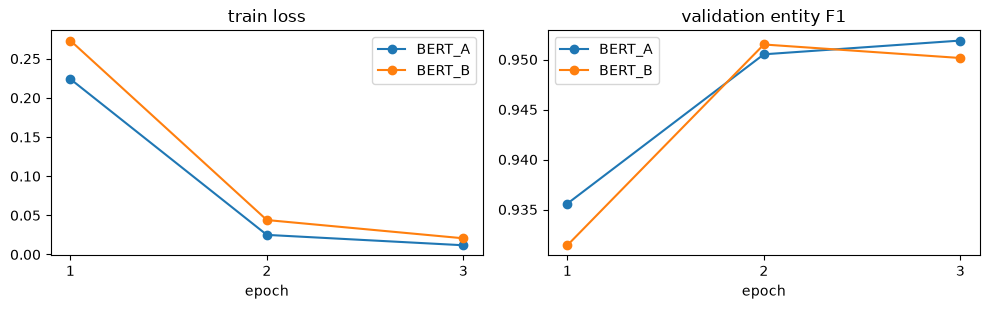

In [13]:
rows = []
for n in ("BERT_A", "BERT_B"):
    r = runs[n]; em = entity_metrics(gold, r["test_pred"])["micro"]
    rows.append({"Strategy": "A — subword đầu, còn lại −100" if n == "BERT_A" else "B — lan truyền nhãn (B-X → I-X)", "Test entity F1": round(em["f1"], 4),
                 "Precision": round(em["precision"], 4), "Recall": round(em["recall"], 4), "Val F1 (best)": round(max(r["hist"]["val_f1"]), 4),
                 "% token bị IGNORE": round(r["n_ignored"] / r["n_tokens"] * 100, 1), "Best epoch": r["best_epoch"], "Train time (s)": round(r["train_time"])})
    log("alignment_strategy", n, "test_f1", round(em["f1"], 4))
display(pd.DataFrame(rows).set_index("Strategy"))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for n in runs:
    e = range(1, EPOCHS + 1); ax[0].plot(e, runs[n]["hist"]["train_loss"], "o-", label=n); ax[1].plot(e, runs[n]["hist"]["val_f1"], "o-", label=n)
ax[0].set_title("train loss"); ax[1].set_title("validation entity F1")
for a in ax: a.set_xlabel("epoch"); a.set_xticks(list(e)); a.legend()
plt.tight_layout(); plt.show()

**Nhận xét alignment strategy:** A (F1 0.915) và B (0.914) gần như bằng nhau; A loại 32.3% token khỏi loss, B chỉ 9.3% (chỉ special token). Vì đánh giá luôn dùng subword đầu tiên, việc gán nhãn cho các mảnh ## sau không thêm thông tin; Strategy A đơn giản và khớp annotation gốc hơn nên được chọn. B hội tụ sớm hơn (best epoch 2) nhưng không tốt hơn.

## 25–27. Application — Information Extraction (Option A — News)
`information_extraction.NERExtractor`: raw text → tách word → BERT NER → BIO spans → JSON. Đánh giá trên **30 câu tin tức tự viết** (không thuộc CoNLL-2003, nhiều tên sau năm 1996) với gold annotation tự gán; entity đúng khi trùng cả loại và chuỗi.

In [14]:
from information_extraction import NERExtractor, evaluate_ie, IE_EVAL
ie = NERExtractor("cache/BERT_A_weights_fp16.pt", device="cpu")
for s in ["Barack Obama visited Paris.", "Elon Musk founded SpaceX in California.", "University of California Berkeley researchers met officials from the World Bank in Hanoi."]:
    print(s, "→", json.dumps(ie.extract(s), ensure_ascii=False))
res_ie = evaluate_ie(ie)
print(f"\nMini IE (30 câu, {res_ie['n_gold']} gold entity): Precision {res_ie['precision']:.4f} | Recall {res_ie['recall']:.4f} | F1 {res_ie['f1']:.4f} (TP {res_ie['tp']}, pred {res_ie['n_pred']})")
for k in ("precision", "recall", "f1"): log("mini_ie_news30", "BERT_A", k, round(res_ie[k], 4))
err_rows = [r for r in res_ie["rows"] if r["missing"] or r["spurious"]]
display(pd.DataFrame([{"text": r["text"], "missing (FN)": r["missing"], "spurious (FP)": r["spurious"]} for r in err_rows]))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2209.59it/s]


[transformers] BertModel LOAD REPORT from: bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Barack Obama visited Paris. → {"PERSON": ["Barack Obama"], "LOCATION": ["Paris"]}
Elon Musk founded SpaceX in California. → {"PERSON": ["Elon Musk"], "ORGANIZATION": ["SpaceX"], "LOCATION": ["California"]}


University of California Berkeley researchers met officials from the World Bank in Hanoi. → {"ORGANIZATION": ["University of California Berkeley", "World Bank"], "LOCATION": ["Hanoi"]}



Mini IE (30 câu, 71 gold entity): Precision 0.9437 | Recall 0.9437 | F1 0.9437 (TP 67, pred 71)


,text,missing (FN),spurious (FP)
0,Elon Musk said Tesla will open a new factory i...,"[(PERSON, Elon Musk)]","[(ORGANIZATION, Elon Musk)]"
1,Serena Williams won her first match at Wimbledon.,"[(MISC, Wimbledon)]","[(LOCATION, Wimbledon)]"
2,The New York Times reported that Boeing delaye...,"[(ORGANIZATION, New York Times)]","[(ORGANIZATION, The New York Times)]"
3,Pope Francis celebrated Mass at the Vatican.,"[(PERSON, Francis)]","[(PERSON, Pope Francis)]"


**Nhận xét Mini IE (30 câu tin tức tự viết, 71 gold entity):** P = R = F1 = **0.944** (67/71 đúng), gần bằng test CoNLL dù văn bản mới (OpenAI, Nvidia, Zelensky...). 4 lỗi:
- **Elon Musk → ORGANIZATION**: tên người bị nhầm loại khi đứng trước "said Tesla" (Musk hiếm trong dữ liệu 1996); ở câu "Elon Musk founded SpaceX" thì đúng PERSON → phụ thuộc ngữ cảnh.
- **Wimbledon → LOCATION** thay vì MISC (giải đấu): trong CoNLL "Wimbledon" thường là địa danh/đội bóng, nhập nhằng thật.
- **"The New York Times"** và **"Pope Francis"**: model gộp "The" và chức danh "Pope" vào entity, trong khi gold mình gán theo quy ước CoNLL (không gồm mạo từ, chức danh): lỗi **ranh giới** do quy ước annotation.
Đây vẫn là đánh giá trên tập nhỏ do mình tự gán nhãn, nên chỉ mang tính tham khảo.

## Lưu kết quả

In [15]:
with open("results.csv", "w", newline="", encoding="utf8") as f:
    wr = csv.writer(f); wr.writerow(["experiment", "config", "metric", "value"]); wr.writerows(RESULTS)
print(len(RESULTS), "rows → results.csv")

40 rows → results.csv
